# Tasas anuales y cambios

Celda 1: carga

In [15]:
%pip install scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

BASE      = Path(r"C:\Users\fsociety\Videos\Proyecto_EEVV")
PROCESADO = BASE / "datos" / "procesado"
ORO       = BASE / "datos" / "oro"

defun = pd.read_parquet(PROCESADO / "defunciones_primera_infancia_pacifico.parquet")
nac   = pd.read_parquet(PROCESADO / "nacimientos_pacifico.parquet")
print("Defunciones:", defun.shape, "| Nacimientos:", nac.shape)

Defunciones: (3217, 67) | Nacimientos: (211367, 44)


Celda 2: funciones de apoyo

In [17]:
def tasa_ic(defunciones, nacimientos, por=1000, nivel=0.95):
    a = 1 - nivel
    d = defunciones.astype(float)
    inf = np.where(d > 0, chi2.ppf(a / 2, 2 * d) / 2, 0.0)
    sup = chi2.ppf(1 - a / 2, 2 * (d + 1)) / 2
    return pd.DataFrame({"defunciones": defunciones, "nacimientos": nacimientos,
                         "tasa":   d   / nacimientos * por,
                         "ic_inf": inf / nacimientos * por,
                         "ic_sup": sup / nacimientos * por})

def con_region(df):
    por_dpto = df.assign(territorio=df["dpto_residencia_nombre"].astype(str))
    region   = df.assign(territorio="Región Pacífica")
    return pd.concat([por_dpto, region], ignore_index=True)

d_ext = con_region(defun)
n_ext = con_region(nac)

Celda 3: tasas anuales

In [18]:
INDICADORES = {
    "Neonatal":                    ["Neonatal"],
    "Posneonatal":                 ["Posneonatal"],
    "Infantil (menores de 1 año)": ["Neonatal", "Posneonatal"],
    "Menores de 5 años":           ["Neonatal", "Posneonatal", "1 a 4 años"],
}

nac_t = n_ext.groupby(["territorio", "anio"]).size()
tablas = []
for nombre, grupos in INDICADORES.items():
    d = (d_ext[d_ext["grupo_edad_analisis"].isin(grupos)]
         .groupby(["territorio", "anio"]).size()
         .reindex(nac_t.index, fill_value=0))
    tablas.append(tasa_ic(d, nac_t).assign(indicador=nombre))

tasas_anuales = (pd.concat(tablas).reset_index()
                 .set_index(["indicador", "territorio", "anio"]).sort_index())

tasas_anuales.apply(lambda r: f"{r.tasa:.1f} ({r.ic_inf:.1f}-{r.ic_sup:.1f})", axis=1).unstack("anio")

anio                                                     2022  \
indicador                   territorio                          
Infantil (menores de 1 año) Cauca             11.1 (9.5-12.8)   
                            Chocó            27.3 (23.6-31.3)   
                            Nariño            10.1 (8.5-11.9)   
                            Región Pacífica  11.8 (11.0-12.6)   
                            Valle del Cauca    9.9 (9.0-11.0)   
Menores de 5 años           Cauca            13.6 (11.9-15.5)   
                            Chocó            37.6 (33.3-42.3)   
                            Nariño           13.7 (11.8-15.8)   
                            Región Pacífica  14.9 (14.0-15.8)   
                            Valle del Cauca  11.7 (10.7-12.8)   
Neonatal                    Cauca               6.4 (5.2-7.8)   
                            Chocó            14.7 (12.1-17.8)   
                            Nariño              6.3 (5.1-7.8)   
                            Región Pacífica     7.3 (6.7-7.9)   
                            Valle del Cauca     6.6 (5.8-7.4)   
Posneonatal                 Cauca               4.6 (3.7-5.8)   
                            Chocó            12.5 (10.1-15.4)   
                            Nariño              3.8 (2.8-4.9)   
                            Región Pacífica     4.5 (4.1-5.0)   
                            Valle del Cauca     3.3 (2.8-3.9)   

anio                                                     2023  \
indicador                   territorio                          
Infantil (menores de 1 año) Cauca            11.8 (10.1-13.8)   
                            Chocó            29.1 (25.1-33.5)   
                            Nariño            10.1 (8.4-12.0)   
                            Región Pacífica  12.2 (11.4-13.1)   
                            Valle del Cauca   10.1 (9.1-11.2)   
Menores de 5 años           Cauca            15.4 (13.4-17.6)   
                            Chocó            40.5 (35.8-45.6)   
                            Nariño           13.4 (11.5-15.6)   
                            Región Pacífica  15.6 (14.7-16.5)   
                            Valle del Cauca  11.9 (10.8-13.0)   
Neonatal                    Cauca               7.4 (6.1-9.0)   
                            Chocó             10.8 (8.5-13.7)   
                            Nariño              5.6 (4.3-7.0)   
                            Región Pacífica     7.0 (6.4-7.6)   
                            Valle del Cauca     6.6 (5.8-7.5)   
Posneonatal                 Cauca               4.4 (3.4-5.6)   
                            Chocó            18.2 (15.1-21.8)   
                            Nariño              4.5 (3.4-5.9)   
                            Región Pacífica     5.3 (4.7-5.8)   
                            Valle del Cauca     3.5 (2.9-4.2)   

anio                                                     2024  
indicador                   territorio                         
Infantil (menores de 1 año) Cauca              9.2 (7.6-11.0)  
                            Chocó            29.3 (25.1-34.1)  
                            Nariño            10.5 (8.7-12.6)  
                            Región Pacífica  12.1 (11.3-13.0)  
                            Valle del Cauca   10.7 (9.7-11.9)  
Menores de 5 años           Cauca             11.4 (9.6-13.5)  
                            Chocó            42.1 (37.0-47.7)  
                            Nariño           14.0 (11.9-16.3)  
                            Región Pacífica  15.3 (14.3-16.3)  
                            Valle del Cauca  12.4 (11.2-13.7)  
Neonatal                    Cauca               6.2 (4.9-7.7)  
                            Chocó             11.3 (8.7-14.3)  
                            Nariño              7.1 (5.6-8.8)  
                            Región Pacífica     7.4 (6.8-8.1)  
                            Valle del Cauca     7.3 (6.4-8.3)  
Posneonatal                 Cauca               3.

Celda 4: ¿cambió algo respecto a 2022?

In [19]:
base = tasas_anuales.xs(2022, level="anio")
filas = []
for anio in [2023, 2024]:
    act = tasas_anuales.xs(anio, level="anio")
    rr = act["tasa"] / base["tasa"]
    ee = np.sqrt(1 / act["defunciones"] + 1 / base["defunciones"])
    filas.append(pd.DataFrame({"anio": anio, "razon": rr,
                               "ic_inf": np.exp(np.log(rr) - 1.96 * ee),
                               "ic_sup": np.exp(np.log(rr) + 1.96 * ee)}))

razones = pd.concat(filas).reset_index()
razones["concluyente"] = np.where((razones["ic_inf"] > 1) | (razones["ic_sup"] < 1), "Sí", "No")
razones[razones["concluyente"] == "Sí"].round(2)

,indicador,territorio,anio,razon,ic_inf,ic_sup,concluyente
11,Neonatal,Chocó,2023,0.74,0.55,0.99,Sí
16,Posneonatal,Chocó,2023,1.45,1.11,1.91,Sí
18,Posneonatal,Región Pacífica,2023,1.16,1.00,1.34,Sí
35,Posneonatal,Cauca,2024,0.65,0.44,0.96,Sí
36,Posneonatal,Chocó,2024,1.44,1.09,1.91,Sí


Celda 5: grupo de 1 a 4 años (conteos)

In [20]:
d_ext[d_ext["grupo_edad_analisis"] == "1 a 4 años"].groupby(["territorio", "anio"]).size().unstack("anio")

anio,2022,2023,2024
territorio,,,
Cauca,42,50,28
Chocó,75,76,75
Nariño,51,42,39
Región Pacífica,242,233,197
Valle del Cauca,74,65,55


Celda 6: gráfico

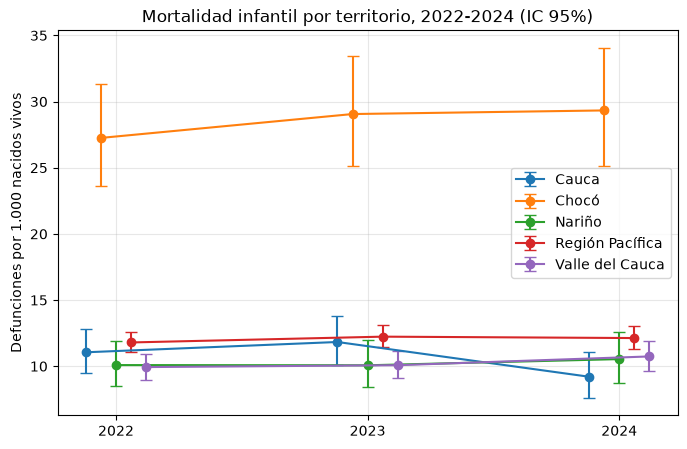

In [21]:
inf_ = tasas_anuales.xs("Infantil (menores de 1 año)", level="indicador").reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
for i, (terr, g) in enumerate(inf_.groupby("territorio")):
    x = g["anio"] + (i - 2) * 0.06
    ax.errorbar(x, g["tasa"], yerr=[g["tasa"] - g["ic_inf"], g["ic_sup"] - g["tasa"]],
                marker="o", capsize=4, label=terr)
ax.set_xticks([2022, 2023, 2024])
ax.set_ylabel("Defunciones por 1.000 nacidos vivos")
ax.set_title("Mortalidad infantil por territorio, 2022-2024 (IC 95%)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Celda 7: guardar en la capa oro

In [22]:
ORO.mkdir(parents=True, exist_ok=True)
tasas_anuales.reset_index().to_parquet(ORO / "tasas_anuales_infantil.parquet", index=False)
razones.to_parquet(ORO / "razones_tasas_vs_2022.parquet", index=False)
print("Guardado en", ORO)

Guardado en C:\Users\fsociety\Videos\Proyecto_EEVV\datos\oro


## Serie mensual de la región

Celda 8: serie mensual

In [23]:
nac_m = n_ext.groupby(["territorio", "anio", "mes"]).size()
tablas = []
for nombre, grupos in INDICADORES.items():
    d = (d_ext[d_ext["grupo_edad_analisis"].isin(grupos)]
         .groupby(["territorio", "anio", "mes"]).size()
         .reindex(nac_m.index, fill_value=0))
    tablas.append(tasa_ic(d, nac_m).assign(indicador=nombre))

serie_mensual = pd.concat(tablas).reset_index()
serie_mensual["fecha"] = pd.to_datetime(dict(year=serie_mensual["anio"],
                                             month=serie_mensual["mes"], day=1))

INDICADOR = "Infantil (menores de 1 año)"
reg = (serie_mensual[(serie_mensual["territorio"] == "Región Pacífica") &
                     (serie_mensual["indicador"] == INDICADOR)]
       .set_index("fecha").sort_index())
print(serie_mensual.shape, "| meses en la serie regional:", len(reg))

(720, 10) | meses en la serie regional: 36


Celda 9: descomposición en tendencia y estacionalidad

In [24]:
pesos = np.array([1/24] + [1/12] * 11 + [1/24])
reg["tendencia"] = reg["tasa"].rolling(13, center=True).apply(lambda x: np.dot(x, pesos), raw=True)

desvio_mes = (reg["tasa"] - reg["tendencia"]).groupby(reg.index.month).mean()
desvio_mes = desvio_mes - desvio_mes.mean()
reg["estacional"] = reg.index.month.map(desvio_mes)
reg["residuo"]    = reg["tasa"] - reg["tendencia"] - reg["estacional"]

desvio_mes.round(2)

fecha
1     1.92
2     0.97
3     0.28
4    -0.42
5    -0.59
6    -0.24
7    -0.03
8    -0.18
9    -0.46
10   -2.04
11   -0.53
12    1.32
dtype: float64

Celda 10: ¿la estacionalidad es real?

In [25]:
from scipy.stats import chisquare

por_mes = reg.groupby(reg.index.month)[["defunciones", "nacimientos"]].sum()
esperadas = por_mes["nacimientos"] / por_mes["nacimientos"].sum() * por_mes["defunciones"].sum()
prueba = chisquare(por_mes["defunciones"], esperadas)

print(f"Chi-cuadrado = {prueba.statistic:.2f}, p = {prueba.pvalue:.3f}")
(por_mes["defunciones"] / esperadas).round(2)

Chi-cuadrado = 7.53, p = 0.754


fecha
1     1.12
2     1.04
3     0.99
4     1.03
5     0.99
6     0.98
7     0.98
8     1.02
9     0.97
10    0.93
11    0.90
12    1.04
dtype: float64

Celda 11: gráfico de control

In [26]:
p_barra = reg["defunciones"].sum() / reg["nacimientos"].sum()
reg["centro"]  = p_barra * 1000
reg["lim_sup"] = (p_barra + 3 * np.sqrt(p_barra / reg["nacimientos"])) * 1000
reg["lim_inf"] = (p_barra - 3 * np.sqrt(p_barra / reg["nacimientos"])).clip(lower=0) * 1000
reg["fuera"]   = (reg["tasa"] > reg["lim_sup"]) | (reg["tasa"] < reg["lim_inf"])
reg["alerta"]  = (reg["tasa"] - reg["centro"]).abs() > 2/3 * (reg["lim_sup"] - reg["centro"])

print("Línea central:", round(p_barra * 1000, 2))
print("Meses fuera de control (3σ):", reg.index[reg["fuera"]].strftime("%Y-%m").tolist())
print("Meses en alerta (2σ):", reg.index[reg["alerta"]].strftime("%Y-%m").tolist())

Línea central: 12.04
Meses fuera de control (3σ): []
Meses en alerta (2σ): ['2023-12', '2024-11']


Celda 12: gráficos

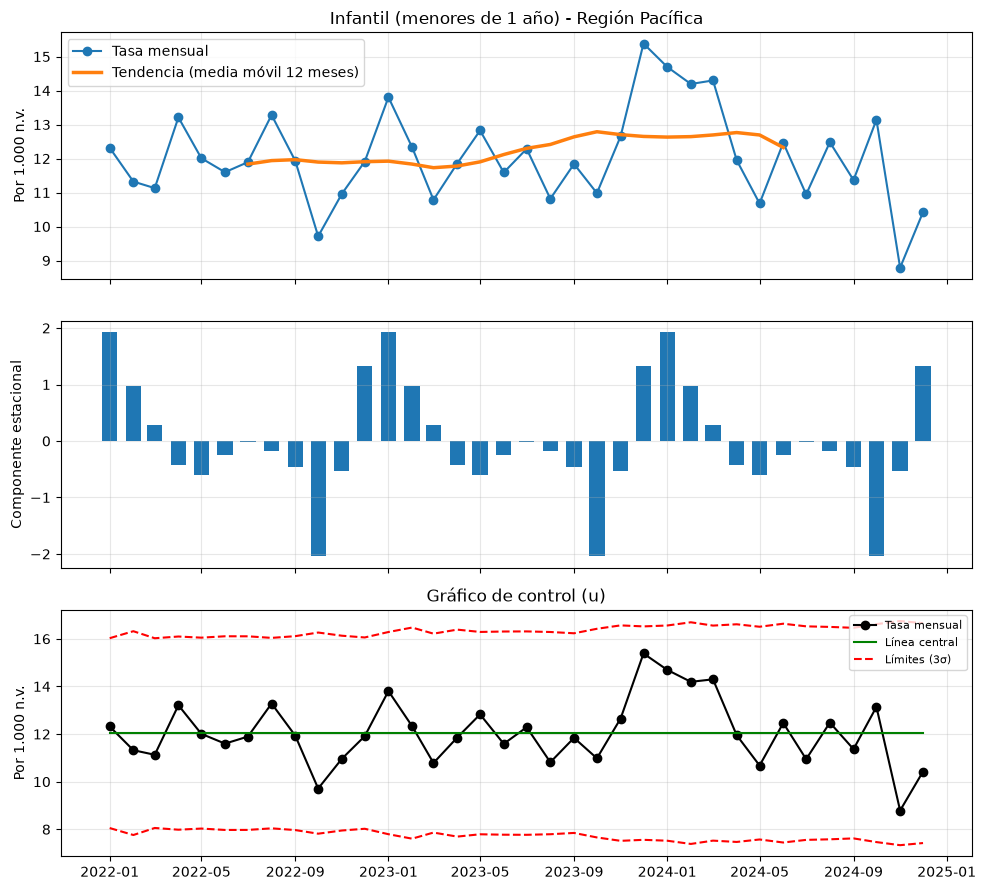

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(reg.index, reg["tasa"], marker="o", label="Tasa mensual")
axes[0].plot(reg.index, reg["tendencia"], lw=2.5, label="Tendencia (media móvil 12 meses)")
axes[0].set_ylabel("Por 1.000 n.v."); axes[0].legend()
axes[0].set_title(f"{INDICADOR} - Región Pacífica")

axes[1].bar(reg.index, reg["estacional"], width=20)
axes[1].set_ylabel("Componente estacional")

axes[2].plot(reg.index, reg["tasa"], marker="o", color="black", label="Tasa mensual")
axes[2].plot(reg.index, reg["centro"], color="green", label="Línea central")
axes[2].plot(reg.index, reg["lim_sup"], "r--", label="Límites (3σ)")
axes[2].plot(reg.index, reg["lim_inf"], "r--")
axes[2].scatter(reg.index[reg["fuera"]], reg.loc[reg["fuera"], "tasa"], color="red", s=80, zorder=3)
axes[2].set_ylabel("Por 1.000 n.v."); axes[2].legend(fontsize=8)
axes[2].set_title("Gráfico de control (u)")

for a in axes:
    a.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Celda 13: guardar en la capa oro

In [28]:
serie_mensual.to_parquet(ORO / "serie_mensual_infantil.parquet", index=False)
print("Guardado:", serie_mensual.shape)

Guardado: (720, 10)


## Fase 2: tasas con población proyectada

Celda 14: leer la población proyectada

In [29]:
PROYECCIONES = BASE / "datos" / "referencia" / "PPED-AreaSexoEdadDep-2018-2050_VP.xlsx"
DPTOS  = {"27": "Chocó", "76": "Valle del Cauca", "19": "Cauca", "52": "Nariño"}
EDADES = ["Total 0 años", "Total 1 año", "Total 2 años", "Total 3 años", "Total 4 años"]

raw = pd.read_excel(PROYECCIONES, sheet_name="PobDepartamentalxÁreaSexoEdad", header=None, dtype=str)
raw.columns = [b if pd.notna(b) else a for a, b in zip(raw.iloc[7].ffill(), raw.iloc[8])]
proy = raw.iloc[9:]
proy = proy[proy["DP"].isin(list(DPTOS)) & (proy["ÁREA GEOGRÁFICA"] == "Total")].copy()
proy["anio"] = proy["AÑO"].astype(int)
proy = proy[proy["anio"].between(2022, 2024)]
proy[EDADES] = proy[EDADES].astype(float)
proy["pob_0_4"] = proy[EDADES].sum(axis=1)
proy["pob_1_4"] = proy[EDADES[1:]].sum(axis=1)
proy["territorio"] = proy["DP"].map(DPTOS)

poblacion = proy[["territorio", "anio", "pob_0_4", "pob_1_4"]]
region = (poblacion.groupby("anio", as_index=False)[["pob_0_4", "pob_1_4"]].sum()
          .assign(territorio="Región Pacífica"))
poblacion = pd.concat([poblacion, region], ignore_index=True)
assert len(poblacion) == 15, "Se esperaban 5 territorios x 3 años"

poblacion.pivot_table(index="territorio", columns="anio", values="pob_0_4").round(0)

anio,2022,2023,2024
territorio,,,
Cauca,125760.0,125292.0,124338.0
Chocó,65087.0,65285.0,65209.0
Nariño,129879.0,129212.0,127947.0
Región Pacífica,615210.0,609982.0,603053.0
Valle del Cauca,294484.0,290193.0,285559.0


Celda 15: tasas por 100.000 niños

In [30]:
POR = 100_000
cie3 = d_ext["causa_basica_cie10"].str[:3]

FILTROS = {
    "Mortalidad de 1 a 4 años":               (d_ext["grupo_edad_analisis"] == "1 a 4 años", "pob_1_4"),
    "Desnutrición (E40-E46)":                 (cie3.between("E40", "E46"), "pob_0_4"),
    "Enfermedad diarreica aguda (A00-A09)":   (cie3.between("A00", "A09"), "pob_0_4"),
    "Infección respiratoria aguda (J00-J22)": (cie3.between("J00", "J22"), "pob_0_4"),
}

pob_acum = poblacion.groupby("territorio")[["pob_0_4", "pob_1_4"]].sum()
tablas = []
for nombre, (filtro, denominador) in FILTROS.items():
    d = d_ext[filtro].groupby("territorio").size().reindex(pob_acum.index, fill_value=0)
    t = tasa_ic(d, pob_acum[denominador], por=POR).rename(columns={"nacimientos": "poblacion"})
    tasa_region = t.loc["Región Pacífica", "tasa"]
    t["tasa_region"] = tasa_region
    t["frente_a_region"] = np.select([t["ic_inf"] > tasa_region, t["ic_sup"] < tasa_region],
                                     ["Por encima", "Por debajo"], "Similar")
    t.loc["Región Pacífica", "frente_a_region"] = "Referencia"
    tablas.append(t.assign(indicador=nombre))

tasas_poblacion = pd.concat(tablas).reset_index()
tasas_poblacion.round(1)

,territorio,defunciones,poblacion,tasa,ic_inf,ic_sup,tasa_region,frente_a_region,indicador
0,Cauca,120,301434.0,39.8,33.0,47.6,45.7,Similar,Mortalidad de 1 a 4 años
1,Chocó,226,156281.0,144.6,126.4,164.7,45.7,Por encima,Mortalidad de 1 a 4 años
2,Nariño,132,310392.0,42.5,35.6,50.4,45.7,Similar,Mortalidad de 1 a 4 años
3,Región Pacífica,672,1471134.0,45.7,42.3,49.3,45.7,Referencia,Mortalidad de 1 a 4 años
4,Valle del Cauca,194,703027.0,27.6,23.8,31.8,45.7,Por debajo,Mortalidad de 1 a 4 años
5,Cauca,12,375390.0,3.2,1.7,5.6,11.0,Por debajo,Desnutrición (E40-E46)
6,Chocó,140,195581.0,71.6,60.2,84.5,11.0,Por encima,Desnutrición (E40-E46)
7,Nariño,15,387038.0,3.9,2.2,6.4,11.0,Por debajo,Desnutrición (E40-E46)
8,Región Pacífica,202,1828245.0,11.0,9.6,12.7,11.0,Referencia,Desnutrición (E40-E46)
9,Valle del Cauca,35,870236.0,4.0,2.8,5.6,11.0,Por debajo,Desnutrición (E40-E46)


Celda 16: guardar

In [31]:
poblacion.to_parquet(ORO / "poblacion_proyectada.parquet", index=False)
tasas_poblacion.to_parquet(ORO / "tasas_poblacion_acumuladas.parquet", index=False)
print("Guardado:", tasas_poblacion.shape)

Guardado: (20, 9)
